# Credit Card Fraud Detection :

Goal: find fraud transactions.

Steps: load data, look at it, prepare it, train models, compare results.

## Step 1: Import libraries

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import average_precision_score
from imblearn.over_sampling import SMOTE

## Step 2: Load the data

In [ ]:
data = pd.read_csv("creditcard.csv")
print("Rows and columns:", data.shape)
data.head()

Rows and columns: (9965, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0


## Step 3: Look at the data

In [ ]:

print("Missing values:", data.isnull().sum().sum())
print(data["Class"].value_counts())

Missing values: 28
Class
0.0    9926
1.0      38
Name: count, dtype: int64


Fraud percentage: 0.381 %


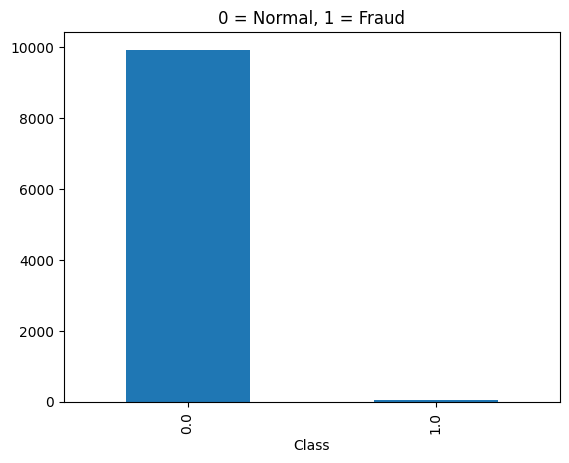

In [ ]:

fraud_percent = data["Class"].mean() * 100
print("Fraud percentage:", round(fraud_percent, 3), "%")
data["Class"].value_counts().plot(kind="bar")
plt.title("0 = Normal, 1 = Fraud")
plt.show()

**Important idea:** if a model says "no fraud" for every transaction, it is still about 99.8% accurate, but it catches **zero** fraud.
So we will **not** use accuracy. We will use **precision** and **recall** instead:

- **Recall** = out of all real frauds, how many did we catch?
- **Precision** = out of all transactions we called fraud, how many really were fraud?

## Step 4: Prepare the data

In [ ]:

scaler = StandardScaler()
data["Amount"] = scaler.fit_transform(data[["Amount"]])
data["Time"] = scaler.fit_transform(data[["Time"]])

X = data.drop("Class", axis=1)
y = data["Class"]

In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 7971
Test rows: 1993


## Step 5: Model 1 - Logistic Regression (baseline)

In [ ]:
model1 = LogisticRegression(max_iter=1000)
model1.fit(X_train, y_train)

pred1 = model1.predict(X_test)
print(classification_report(y_test, pred1))
print(confusion_matrix(y_test, pred1))

              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      1985
         1.0       1.00      0.62      0.77         8

    accuracy                           1.00      1993
   macro avg       1.00      0.81      0.88      1993
weighted avg       1.00      1.00      1.00      1993

[[1985    0]
 [   3    5]]


## Step 6: Model 2 - Logistic Regression with class weights


In [ ]:
model2 = LogisticRegression(max_iter=1000, class_weight="balanced")
model2.fit(X_train, y_train)

pred2 = model2.predict(X_test)
print(classification_report(y_test, pred2))
print(confusion_matrix(y_test, pred2))

              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      1985
         1.0       0.67      0.75      0.71         8

    accuracy                           1.00      1993
   macro avg       0.83      0.87      0.85      1993
weighted avg       1.00      1.00      1.00      1993

[[1982    3]
 [   2    6]]


## Step 7: Model 3 - SMOTE
SMOTE creates extra fake-but-realistic fraud examples so the training data is balanced. Use it on **training data only**, never on test data.

In [ ]:
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Before SMOTE:")
print(y_train.value_counts())
print("After SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
Class
0.0    7941
1.0      30
Name: count, dtype: int64
After SMOTE:
Class
0.0    7941
1.0    7941
Name: count, dtype: int64


In [ ]:
model3 = LogisticRegression(max_iter=1000)
model3.fit(X_train_smote, y_train_smote)

pred3 = model3.predict(X_test)
print(classification_report(y_test, pred3))
print(confusion_matrix(y_test, pred3))

              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      1985
         1.0       0.75      0.75      0.75         8

    accuracy                           1.00      1993
   macro avg       0.87      0.87      0.87      1993
weighted avg       1.00      1.00      1.00      1993

[[1983    2]
 [   2    6]]


## Step 8: Model 4 - Random Forest
A Random Forest is many decision trees voting together. It is usually stronger than Logistic Regression.

In [ ]:
model4 = RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42, n_jobs=-1)
model4.fit(X_train, y_train)

pred4 = model4.predict(X_test)
print(classification_report(y_test, pred4))
print(confusion_matrix(y_test, pred4))

              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      1985
         1.0       1.00      0.62      0.77         8

    accuracy                           1.00      1993
   macro avg       1.00      0.81      0.88      1993
weighted avg       1.00      1.00      1.00      1993

[[1985    0]
 [   3    5]]


## Step 9: Compare all models
We use **PR-AUC** (average precision). Higher is better, and 1.0 is perfect.

In [ ]:

prob1 = model1.predict_proba(X_test)[:, 1]
prob2 = model2.predict_proba(X_test)[:, 1]
prob3 = model3.predict_proba(X_test)[:, 1]
prob4 = model4.predict_proba(X_test)[:, 1]

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Logistic + class weight", "Logistic + SMOTE", "Random Forest"],
    "PR-AUC": [
        average_precision_score(y_test, prob1),
        average_precision_score(y_test, prob2),
        average_precision_score(y_test, prob3),
        average_precision_score(y_test, prob4),
    ],
})
results

,Model,PR-AUC
0,Logistic Regression,0.894345
1,Logistic + class weight,0.855952
2,Logistic + SMOTE,0.865132
3,Random Forest,0.972222


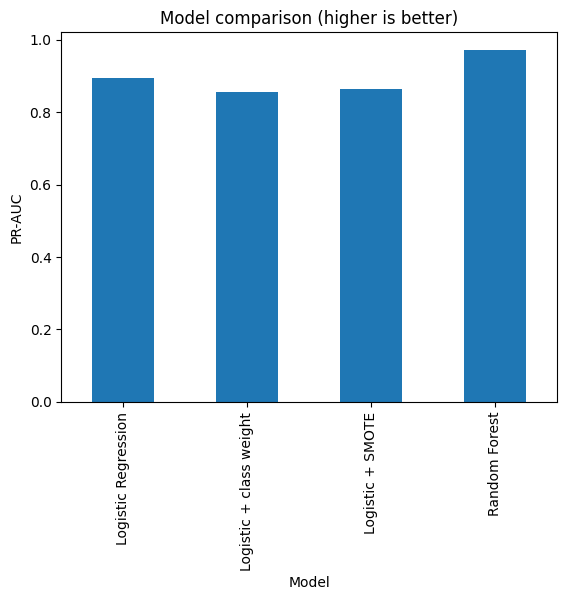

In [ ]:
results.plot(x="Model", y="PR-AUC", kind="bar", legend=False)
plt.title("Model comparison (higher is better)")
plt.ylabel("PR-AUC")
plt.show()

## Step 11: Which columns matter most?

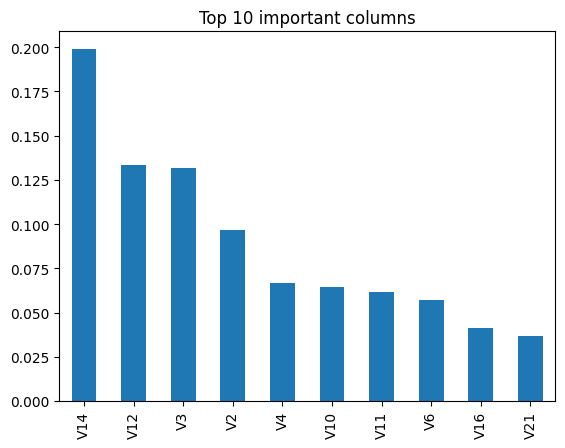

In [ ]:
importance = pd.Series(model4.feature_importances_, index=X.columns)
top10 = importance.sort_values(ascending=False).head(10)

top10.plot(kind="bar")
plt.title("Top 10 important columns")
plt.show()